# Birth only vs death only
Do individuals known only by their birth and those known only by their death spread over the centuries in the same way? Birth-only individuals are placed at their birth year, death-only individuals at their death year.

In [1]:
import duckdb
import matplotlib.pyplot as plt
import polars as pl
from matplotlib.ticker import FuncFormatter
from style import *

DB_PATH = '../data/cultura/humans_clean_non_enriched_v3.duckdb'

FIRST_CENTURY = -1000
LAST_CENTURY = 1900
LIVING_CUTOFF = 1900
PRECISE = ['day', 'month', 'year', 'decade']
MID_DECADE = 5

SERIES_COLORS = {
    'Birth date only (at birth)': BLUE,
    'Death date only (at death)': ORANGE,
}

apply_style()

connection = duckdb.connect(DB_PATH, read_only=True)

## Load the data
One row per individual with a birth date but no death date, or a death date but no birth date. Only dates precise to the decade or finer are kept; a decade is moved to its middle.

In [2]:
one_sided = connection.execute('''
    SELECT entity.qid AS qid,
           CASE WHEN len(death_date) = 0 THEN 'Birth date only (at birth)' ELSE 'Death date only (at death)' END AS series,
           CASE WHEN len(death_date) = 0 THEN birth_date[1] ELSE death_date[1] END AS date
    FROM individual
    WHERE (len(birth_date) > 0) != (len(death_date) > 0)
''').pl().with_columns(
    pl.col('date').struct.field('year').alias('year'),
    pl.col('date').struct.field('precision').alias('precision'),
).drop('date')
assert one_sided['qid'].n_unique() == one_sided.height
print(f'{one_sided.height:,} individuals with only one of birth or death')
one_sided.group_by('series').len('individuals').sort('series')

4,479,434 individuals with only one of birth or death


series,individuals
str,u32
"""Birth date only (at birth)""",4217948
"""Death date only (at death)""",261486


In [3]:
precise = one_sided.filter(pl.col('precision').is_in(PRECISE)).with_columns(
    pl.when(pl.col('precision') == 'decade').then(pl.col('year') + MID_DECADE).otherwise(pl.col('year')).alias('year'))
print(f'{one_sided.height - precise.height:,} individuals left out: date coarser than a decade')
precise.sample(5, seed=0)

90,206 individuals left out: date coarser than a decade


qid,series,year,precision
str,str,i64,str
"""Q133473704""","""Birth date only (at birth)""",1959,"""year"""
"""Q135220264""","""Birth date only (at birth)""",1975,"""year"""
"""Q133724898""","""Birth date only (at birth)""",1953,"""year"""
"""Q102317105""","""Birth date only (at birth)""",1979,"""day"""
"""Q1730544""","""Birth date only (at birth)""",1982,"""day"""


In [4]:
centuries = precise.with_columns((pl.col('year') // 100 * 100).alias('century_start'))
in_range = centuries.filter(pl.col('century_start').is_between(FIRST_CENTURY, LAST_CENTURY))
print(f'{centuries.height - in_range.height:,} individuals outside {FIRST_CENTURY}–{LAST_CENTURY + 99} left out')

def century_counts(frame):
    return (frame.group_by('series', 'century_start').len('individuals')
            .with_columns((100 * pl.col('individuals') / pl.col('individuals').sum().over('series')).alias('share'))
            .sort('series', 'century_start'))


counts = century_counts(in_range)
counts_before_1900 = century_counts(in_range.filter(pl.col('century_start') < LIVING_CUTOFF))
counts.pivot('series', index='century_start', values='individuals').sort('century_start')

195,230 individuals outside -1000–1999 left out


century_start,Birth date only (at birth),Death date only (at death)
i64,u32,u32
-1000,null,1
-900,1,21
-800,6,42
-700,6,71
-600,34,87
…,…,…
1500,17211,18459
1600,25557,30094
1700,39985,27963


## Figures

In [5]:
SHARE = FuncFormatter(lambda x, _: f'{x:g}%')


def plot_series(counts, column, formatter):
    fig, ax = plt.subplots(figsize=FIGSIZE_WIDE)
    for name, color in SERIES_COLORS.items():
        frame = counts.filter(pl.col('series') == name)
        total = frame['individuals'].sum()
        ax.plot(frame['century_start'], frame[column], marker='o', markersize=5, color=color, label=f'{name} — {total:,}')
    ax.set_yscale('log')
    ax.yaxis.set_major_formatter(formatter)
    ax.set_xlim(FIRST_CENTURY - 50, counts['century_start'].max() + 50)
    ax.set_xlabel('Century (start year)')
    ax.grid(axis='y')
    ax.legend(loc='upper left')
    plt.show()

### Figure 1: Individuals per century, birth only vs death only
Number of individuals, log scale.

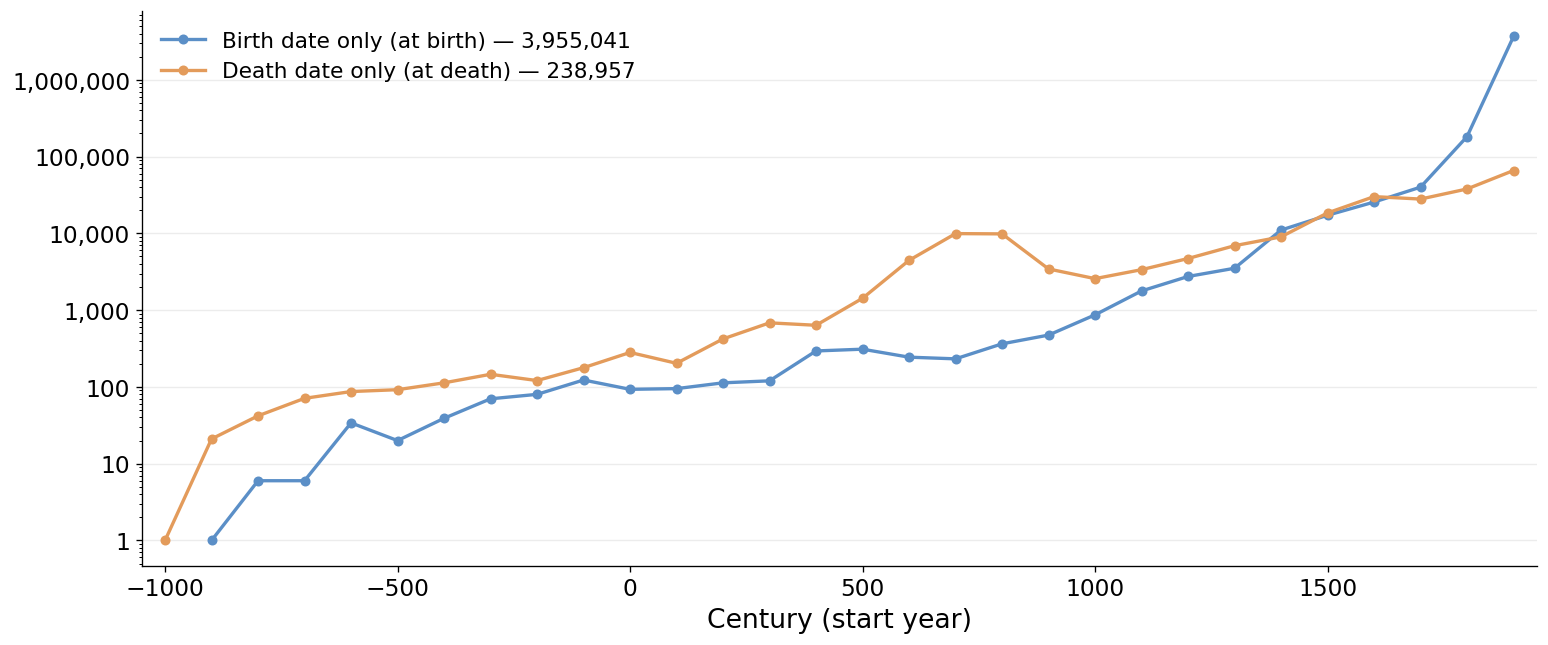

In [6]:
plot_series(counts, 'individuals', THOUSANDS)

### Figure 2: Share of each group per century
Each series sums to 100%, so the two shapes can be compared directly. Log scale.

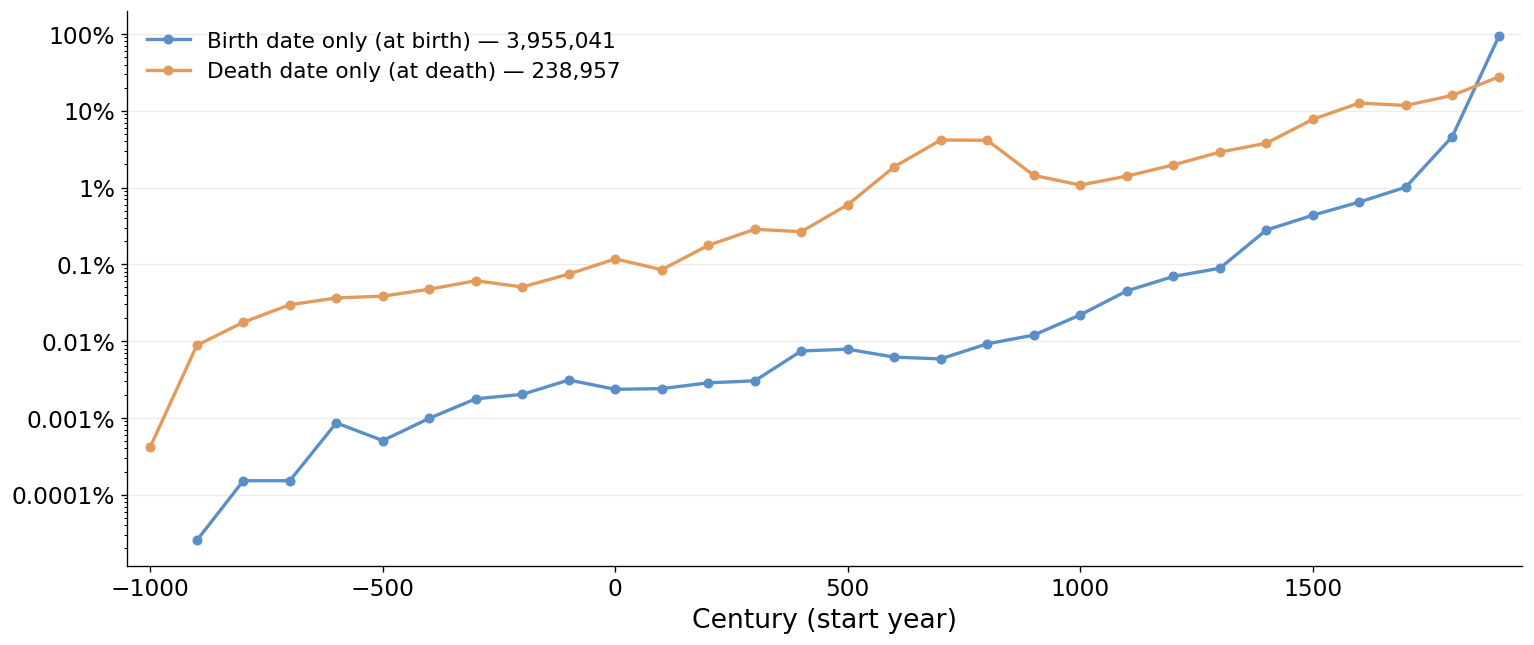

In [7]:
plot_series(counts, 'share', SHARE)

### Figure 3: Share of each group per century, before 1900
The 1900s are dropped, because most people born then with no death date are still alive. Shares are recomputed on the remaining centuries.

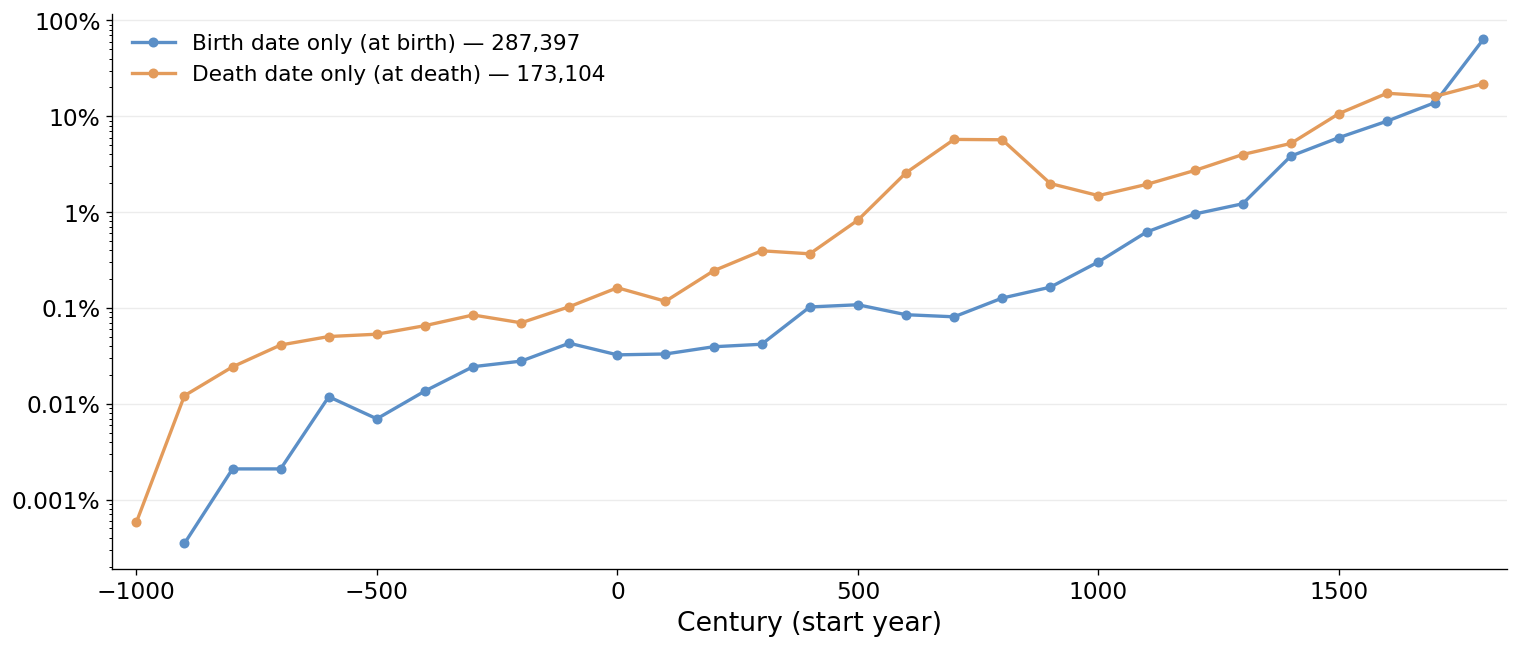

In [8]:
plot_series(counts_before_1900, 'share', SHARE)